In [1]:
import numpy             as np
import matplotlib.pyplot as plt
import seaborn           as sns
import multiprocess      as mp
import pandas            as pd

from libraries                         import utils
from pymatgen.analysis.phase_diagram   import PhaseDiagram
from pymatgen.entries.computed_entries import ComputedEntry
from os                                import path
from sklearn                           import model_selection
from sklearn.ensemble                  import RandomForestRegressor
from sklearn.neural_network            import MLPRegressor
from sklearn.model_selection           import ShuffleSplit

#sns.set_theme()

Defining general output properties

In [2]:
linewidth      = 0.5
footnotesize   = 8
s_footnotesize = 10*0.8
eps_dpi        = 100
png_dpi        = 400
output_folder  = 'output/ternary_chalcohalides'
input_folder   = 'input/ternary_chalcohalides'

# Iterations might be run from here

In [3]:
miller_index = '011'

In [4]:
vbm     = np.loadtxt(f'{input_folder}/results_vbm_{miller_index}.txt')
bandgap = np.loadtxt(f'{input_folder}/results_band_gap.txt')

In [5]:
# Convert the array to a Pandas DataFrame
vbmd = pd.DataFrame(vbm, columns=["x", "y", "z", "VBM"])
vbmd.set_index(["x", "y", "z"], inplace=True)

bandgapd = pd.DataFrame(bandgap, columns=["x", "y", "z", "bandgap"])
bandgapd.set_index(["x", "y", "z"], inplace=True)

# Combine the DataFrames, aligning by index
data = pd.concat([vbmd, bandgapd], axis=1)

data['CBM'] = data['VBM'] + data['bandgap']
data

VBM   bandgap       CBM
x    y    z                                 
0.00 0.00 0.00 -6.283043  1.524687 -4.758356
          0.05 -6.297463  1.529355 -4.768107
          0.10 -6.309342  1.532872 -4.776469
          0.15 -6.316886  1.536684 -4.780202
          0.20 -6.324363  1.542081 -4.782282
...                  ...       ...       ...
0.95 0.90 0.10       NaN  1.777273       NaN
     0.95 0.05       NaN  1.812115       NaN
1.00 0.20 0.15       NaN  1.357448       NaN
     0.25 0.20       NaN  1.373054       NaN
     0.90 0.05       NaN  1.755392       NaN

[1901 rows x 3 columns]

In [6]:
import pandas as pd


data = data.sort_index()


def find_largest_jump(data, varying, prop):
    """
    Find largest consecutive jump of prop along varying coordinate.
    """

    fixed = [i for i in ["x", "y", "z"] if i != varying]

    best = None

    # Loop over fixed coordinates
    for fixed_values, group in data.groupby(level=fixed):

        group = group.sort_index(level=varying)

        values = group[prop]

        # Difference between consecutive points
        jumps = values.diff().abs()

        if jumps.dropna().empty:
            continue

        max_jump = jumps.max()
        idx = jumps.idxmax()

        # Get varying coordinate positions
        coords = group.index.get_level_values(varying)
        pos = coords.get_loc(idx[["x", "y", "z"].index(varying)])

        coord2 = coords[pos]
        coord1 = coords[pos - 1]

        # Store if largest so far
        if best is None or max_jump > best["jump"]:
            composition1 = dict(zip(fixed, fixed_values))
            composition2 = dict(zip(fixed, fixed_values))

            composition1[varying] = coord1
            composition2[varying] = coord2

            best = {
                "jump": max_jump,
                "composition1": composition1,
                "composition2": composition2
            }

    return best


# Run for all directions and properties
for direction in ["x", "y", "z"]:
    for prop in ["VBM", "CBM"]:

        result = find_largest_jump(data, direction, prop)

        print(f"\nLargest {prop} jump along {direction}:")
        print("Composition 1:", result["composition1"])
        print("Composition 2:", result["composition2"])
        print(f"Change = {result['jump']:.6f}")


Largest VBM jump along x:
Composition 1: {'y': np.float64(0.8), 'z': np.float64(0.7000000000000001), 'x': np.float64(0.0)}
Composition 2: {'y': np.float64(0.8), 'z': np.float64(0.7000000000000001), 'x': np.float64(1.0)}
Change = 0.252439

Largest CBM jump along x:
Composition 1: {'y': np.float64(0.65), 'z': np.float64(0.45), 'x': np.float64(0.0)}
Composition 2: {'y': np.float64(0.65), 'z': np.float64(0.45), 'x': np.float64(1.0)}
Change = 0.478134

Largest VBM jump along y:
Composition 1: {'x': np.float64(0.9500000000000001), 'z': np.float64(1.0), 'y': np.float64(0.0)}
Composition 2: {'x': np.float64(0.9500000000000001), 'z': np.float64(1.0), 'y': np.float64(1.0)}
Change = 0.364325

Largest CBM jump along y:
Composition 1: {'x': np.float64(0.9), 'z': np.float64(0.05), 'y': np.float64(0.0)}
Composition 2: {'x': np.float64(0.9), 'z': np.float64(0.05), 'y': np.float64(1.0)}
Change = 0.200152

Largest VBM jump along z:
Composition 1: {'x': np.float64(0.9), 'y': np.float64(0.05), 'z': np.fl

In [6]:
data.to_excel('011-output.xlsx')

In [6]:
# Maximum value and its index
max_value = data['CBM'].max()
max_index = data['CBM'].idxmax()

# Minimum value and its index
min_value = data['CBM'].min()
min_index = data['CBM'].idxmin()

print(f"Maximum: {max_value} at {data.loc[[max_index]]}")
print(f"Minimum: {min_value} at {data.loc[[min_index]]}")

Maximum: -4.174016165987345 at                    VBM   bandgap       CBM
x   y   z                                 
0.0 1.0 0.15 -6.155009  1.980993 -4.174016
Minimum: -4.866256547646717 at                   VBM   bandgap       CBM
x   y   z                                
1.0 0.0 0.0 -6.168275  1.302018 -4.866257


In [7]:
# Maximum value and its index
max_value = data['VBM'].max()
max_index = data['VBM'].idxmax()

# Minimum value and its index
min_value = data['VBM'].min()
min_index = data['VBM'].idxmin()

print(f"Maximum: {max_value} at {data.loc[[max_index]]}")
print(f"Minimum: {min_value} at {data.loc[[min_index]]}")

Maximum: -5.819747785585406 at                   VBM   bandgap       CBM
x   y   z                                
0.0 0.0 1.0 -5.819748  1.482574 -4.337174
Minimum: -6.330147424623264 at                    VBM   bandgap      CBM
x   y   z                                
1.0 1.0 0.25 -6.330147  1.808288 -4.52186


In [8]:
CO2_CO    = -3.91
CO2_CH3OH = -4.06
CO2_CH4   = -4.20
N2_NH3    = -4.35
H_H2      = -4.44

for HTL in [CO2_CO, CO2_CH3OH, CO2_CH4, N2_NH3, H_H2]:
    print(HTL)
    mask = (data['CBM'] > HTL) & (data['CBM'] < HTL + 0.5)
    print(data.index[mask])

-3.91
MultiIndex([], names=['x', 'y', 'z'])
-4.06
MultiIndex([], names=['x', 'y', 'z'])
-4.2
MultiIndex([(                0.0,                0.9,                 0.1),
            (                0.0,                0.9, 0.15000000000000002),
            (                0.0,                0.9,                 0.2),
            (                0.0,                0.9,                0.25),
            (                0.0, 0.9500000000000001,                0.05),
            (                0.0, 0.9500000000000001,                 0.1),
            (                0.0, 0.9500000000000001, 0.15000000000000002),
            (                0.0, 0.9500000000000001,                 0.2),
            (                0.0, 0.9500000000000001,                0.25),
            (                0.0, 0.9500000000000001, 0.30000000000000004),
            (                0.0,                1.0,                 0.0),
            (                0.0,                1.0,                0.

In [9]:
df = data.reset_index()   # x, y, z become columns

CdS
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


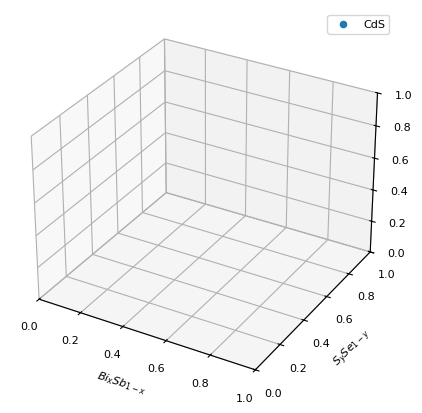

WS2
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


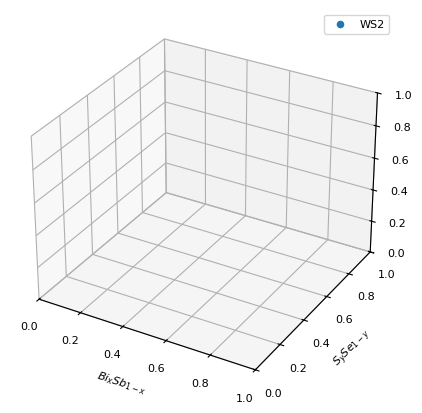

TiO2
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


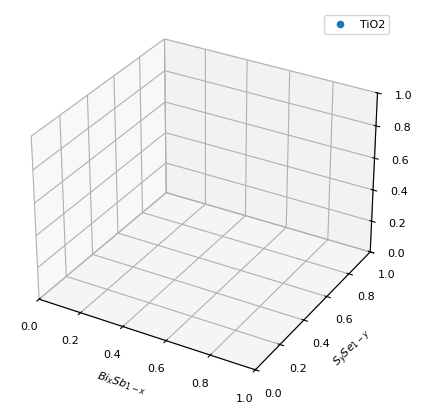

ZnO
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


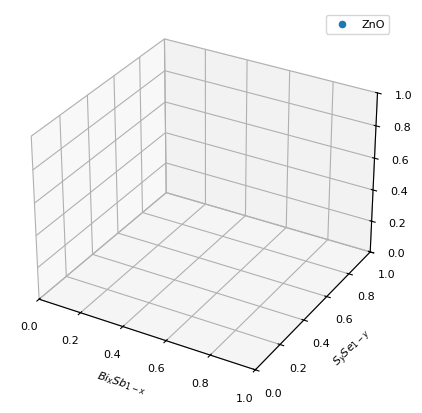

SnO2
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


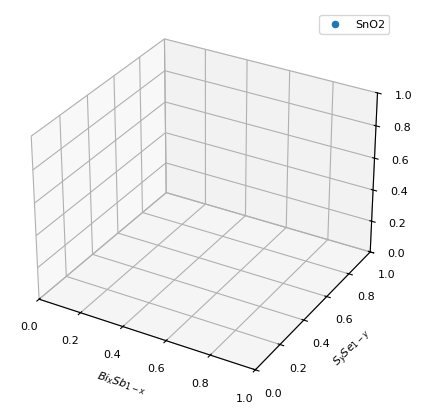

Spiro-MeoTAD
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


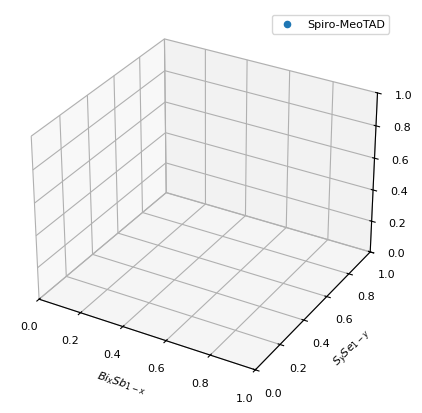

PEDOT:PSS
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


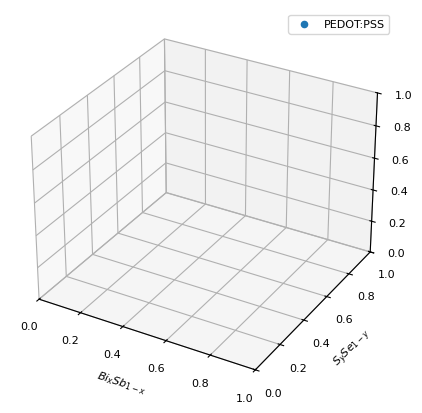

P3HT
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


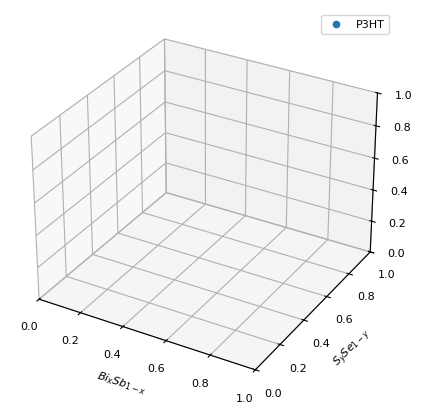

MoSe2
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


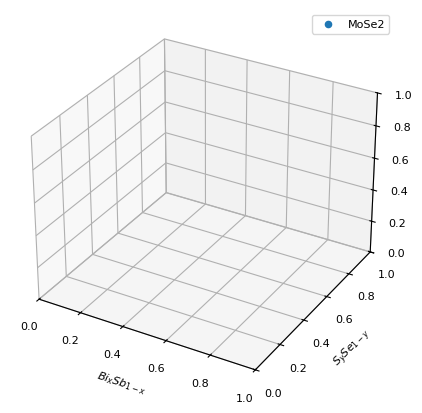

V2O5
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


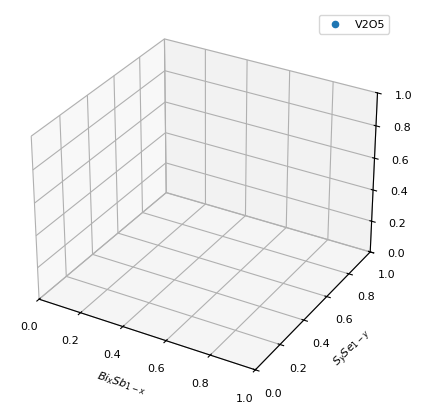

In [10]:
levels = {
    "CO2→CO": -3.91,
    "CO2→CH3OH": -4.06,
    "CO2→CH4": -4.20,
    "N2→NH3": -4.35,
    "H→H2": -4.44
}

levels = {
    "CdS": -3.85,
    "WS2": -2.95,
    "TiO2": -4.00,
    "ZnO": -4.00,
    "SnO2": -4.00,
    "Spiro-MeoTAD": -2.20,
    "PEDOT:PSS": -3.40,
    "P3HT": -3.50,
    "MoSe2": -3.60,
    "V2O5": -4.00
}

matches = []

for name, HTL in levels.items():
    mask = (df['CBM'] > HTL) & (df['CBM'] < HTL + 0.5)
    
    tmp = df.loc[mask].copy()
    tmp["target"] = name
    
    matches.append(tmp)

matches_df = pd.concat(matches)

for name in levels:
    subset = matches_df[matches_df["target"] == name]
    print(name)
    print(subset)

    fig = plt.figure(figsize=(5, 5))
    ax  = plt.axes(projection='3d')

    ax.scatter(subset["x"], subset["y"], subset["z"], label=name)

    # Setting labels
    ax.set_xlabel(r'$Bi_x Sb_{1-x}$', fontsize=footnotesize)
    ax.set_ylabel(r'$S_y Se_{1-y}$',  fontsize=footnotesize)
    ax.set_zlabel(r'$I_z Br_{1-z}$',  fontsize=footnotesize)

    # Setting number to scale
    ax.tick_params(axis='x', labelsize=footnotesize)
    ax.tick_params(axis='y', labelsize=footnotesize)
    ax.tick_params(axis='z', labelsize=footnotesize)

    # Setting limits
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_zlim(0, 1)

    # Adding legend
    ax.legend(loc='upper right', fontsize=footnotesize)
    ax.grid(alpha=0.4)

    # Saving the figure
    plt.savefig(f'{output_folder}/CBM_{name}_{miller_index}.png', dpi=300)
    plt.show()

CdS
         x    y     z       VBM   bandgap       CBM target
847   0.40  1.0  0.35 -6.270536  1.991015 -4.279521    CdS
848   0.40  1.0  0.40 -6.270287  1.979195 -4.291092    CdS
867   0.45  1.0  0.25 -6.273419  1.992745 -4.280674    CdS
868   0.45  1.0  0.30 -6.276443  1.990878 -4.285565    CdS
869   0.45  1.0  0.35 -6.277207  1.984126 -4.293081    CdS
...    ...  ...   ...       ...       ...       ...    ...
1756  1.00  1.0  0.45 -6.311587  1.734126 -4.577461    CdS
1757  1.00  1.0  0.50 -6.304371  1.716375 -4.587996    CdS
1758  1.00  1.0  0.55 -6.297033  1.698432 -4.598601    CdS
1759  1.00  1.0  0.60 -6.285460  1.678374 -4.607086    CdS
1760  1.00  1.0  0.65 -6.273475  1.658317 -4.615158    CdS

[254 rows x 7 columns]


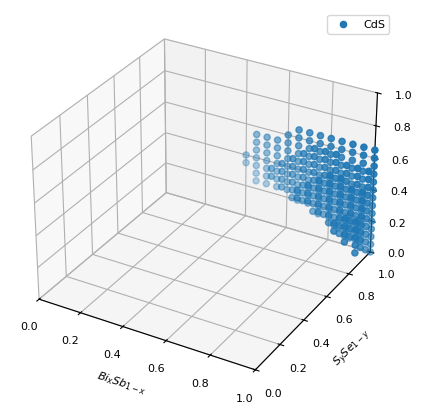

WS2
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


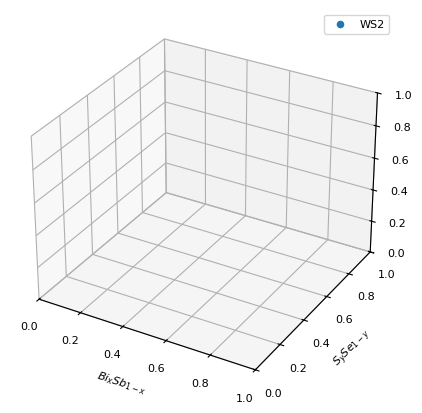

TiO2
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


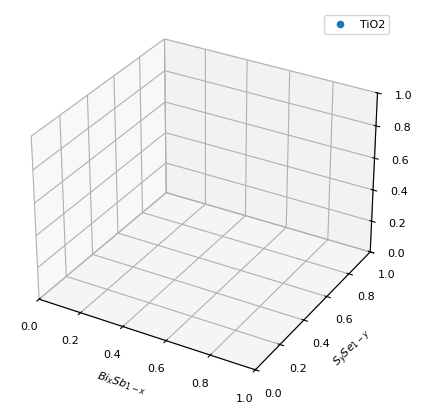

ZnO
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


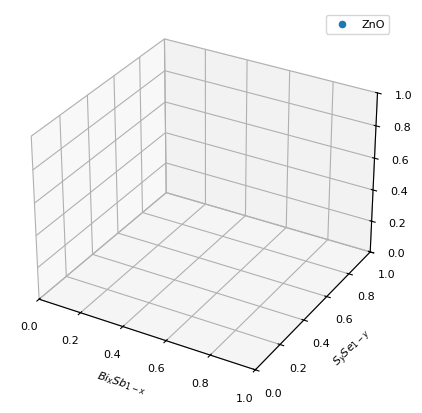

SnO2
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


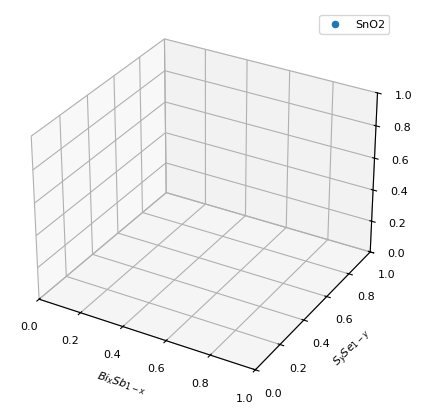

Spiro-MeoTAD
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


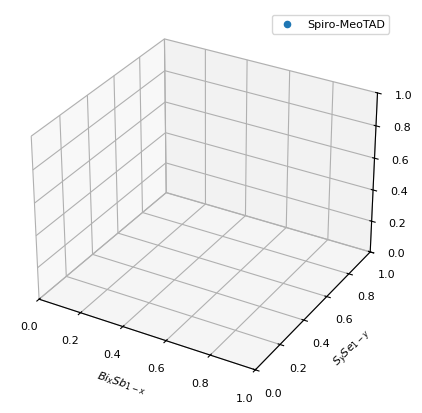

PEDOT:PSS
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


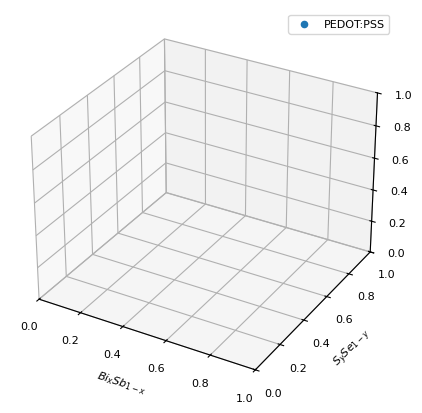

P3HT
Empty DataFrame
Columns: [x, y, z, VBM, bandgap, CBM, target]
Index: []


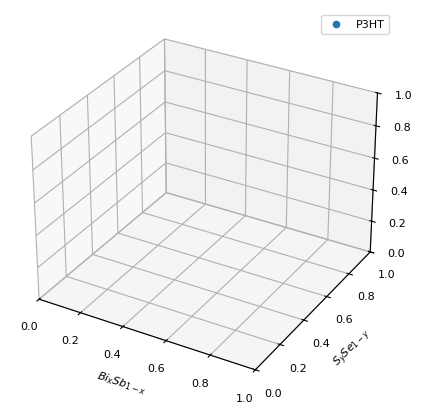

MoSe2
        x     y     z       VBM   bandgap       CBM target
0     0.0  0.00  0.00 -5.873304  1.524687 -4.348617  MoSe2
1     0.0  0.00  0.05 -5.878601  1.529355 -4.349245  MoSe2
2     0.0  0.00  0.10 -5.886466  1.532872 -4.353594  MoSe2
3     0.0  0.00  0.15 -5.893398  1.536684 -4.356714  MoSe2
4     0.0  0.00  0.20 -5.899609  1.542081 -4.357527  MoSe2
...   ...   ...   ...       ...       ...       ...    ...
1626  1.0  0.20  0.65 -6.082385  1.334286 -4.748099  MoSe2
1627  1.0  0.20  0.70 -6.068628  1.327027 -4.741601  MoSe2
1628  1.0  0.20  0.75 -6.052217  1.319241 -4.732976  MoSe2
1636  1.0  0.25  0.60 -6.098937  1.351267 -4.747670  MoSe2
1637  1.0  0.25  0.65 -6.084225  1.345345 -4.738880  MoSe2

[755 rows x 7 columns]


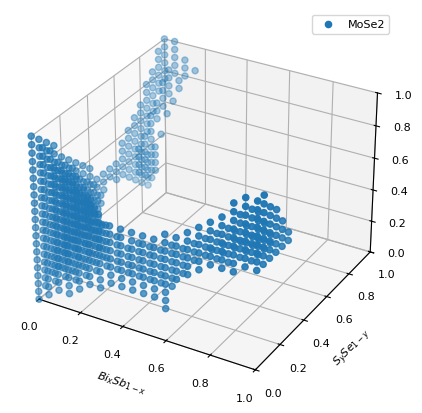

V2O5
         x    y     z       VBM   bandgap       CBM target
629   0.15  1.0  0.15 -6.201639  2.004314 -4.197325   V2O5
630   0.15  1.0  0.20 -6.205503  2.007669 -4.197833   V2O5
631   0.15  1.0  0.25 -6.207821  2.009623 -4.198198   V2O5
632   0.15  1.0  0.30 -6.207721  2.003257 -4.204464   V2O5
633   0.15  1.0  0.35 -6.207610  1.990378 -4.217232   V2O5
...    ...  ...   ...       ...       ...       ...    ...
1760  1.00  1.0  0.65 -6.273475  1.658317 -4.615158   V2O5
1761  1.00  1.0  0.70 -6.258696  1.638043 -4.620652   V2O5
1762  1.00  1.0  0.75 -6.240971  1.617152 -4.623818   V2O5
1763  1.00  1.0  0.80 -6.223245  1.596269 -4.626976   V2O5
1764  1.00  1.0  0.85 -6.205436  1.575322 -4.630113   V2O5

[487 rows x 7 columns]


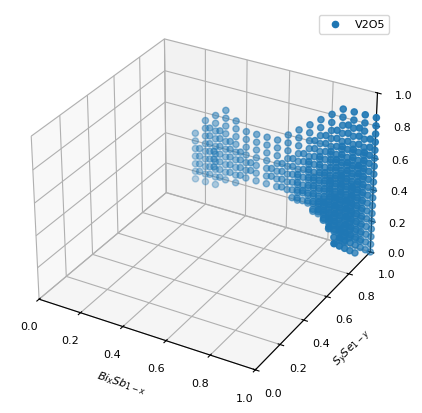

In [11]:
levels = {
    "Br→Br2": -5.51,
    "H2O→O2": -5.67,
    "Cl→Cl2": -5.80,
    "H2O→H2O2": -6.20
}

levels = {
    "CdS": -6.27,
    "WS2": -4.75,
    "TiO2": -7.20,
    "ZnO": -7.30,
    "SnO2": -7.60,
    "Spiro-MeoTAD": -5.20,
    "PEDOT:PSS": -5.00,
    "P3HT": -5.20,
    "MoSe2": -5.60,
    "V2O5": -6.20
}

matches = []

for name, ETL in levels.items():
    mask = (df['VBM'] < ETL) & (df['VBM'] > ETL - 0.5)
    
    tmp = df.loc[mask].copy()
    tmp["target"] = name
    
    matches.append(tmp)

matches_df = pd.concat(matches)

for name in levels:
    subset = matches_df[matches_df["target"] == name]
    print(name)
    print(subset)

    fig = plt.figure(figsize=(5, 5))
    ax  = plt.axes(projection='3d')

    ax.scatter(subset["x"], subset["y"], subset["z"], label=name)

    # Setting labels
    ax.set_xlabel(r'$Bi_x Sb_{1-x}$', fontsize=footnotesize)
    ax.set_ylabel(r'$S_y Se_{1-y}$',  fontsize=footnotesize)
    ax.set_zlabel(r'$I_z Br_{1-z}$',  fontsize=footnotesize)

    # Setting number to scale
    ax.tick_params(axis='x', labelsize=footnotesize)
    ax.tick_params(axis='y', labelsize=footnotesize)
    ax.tick_params(axis='z', labelsize=footnotesize)

    # Setting limits
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_zlim(0, 1)

    # Adding legend
    ax.legend(loc='upper right', fontsize=footnotesize)
    ax.grid(alpha=0.4)

    # Saving the figure
    plt.savefig(f'{output_folder}/VBM_{name}_{miller_index}.png', dpi=300)
    plt.show()

In [13]:
Br_Br2   = -5.51
H2O_O2   = -5.67
Cl_Cl2   = -5.80
H2O_H2O2 = -6.20

for ETL in [Br_Br2, H2O_O2, Cl_Cl2, H2O_H2O2]:
    print(ETL)
    mask = (data['VBM'] < ETL) & (data['VBM'] > ETL - 0.5)
    print(data.index[mask])

-5.51
MultiIndex([(0.0,  0.0,                 0.0),
            (0.0,  0.0,                0.05),
            (0.0,  0.0,                 0.1),
            (0.0,  0.0, 0.15000000000000002),
            (0.0,  0.0,                 0.2),
            (0.0,  0.0,                0.25),
            (0.0,  0.0, 0.30000000000000004),
            (0.0,  0.0, 0.35000000000000003),
            (0.0,  0.0,                 0.4),
            (0.0,  0.0,                0.45),
            ...
            (1.0,  0.0,  0.8500000000000001),
            (1.0,  0.0,                 0.9),
            (1.0,  0.0,  0.9500000000000001),
            (1.0,  0.0,                 1.0),
            (1.0, 0.05,  0.8500000000000001),
            (1.0, 0.05,                 0.9),
            (1.0, 0.05,  0.9500000000000001),
            (1.0, 0.05,                 1.0),
            (1.0,  0.1,  0.8500000000000001),
            (1.0,  0.1,                 0.9)],
           names=['x', 'y', 'z'], length=471)
-5.67
Multi

In [ ]:
valid_xyz = np.array(data.index.to_frame(index=False).values)
for target in ['CBM', 'VBM']:
    threshold = 0.5
    if target == 'VBM':
        # Hydrogen reduction potential
        oxidation_potential = -5.67
        name = f'OER = [{oxidation_potential:.1f}, {oxidation_potential-threshold:.1f}] eV'
        highlight_mask = data[target].between(oxidation_potential - threshold, oxidation_potential)

    elif target == 'CBM':
        # Oxygen reduction potential
        oxidation_potential = -4.44
        name = f'HER = [{oxidation_potential+threshold:.1f}, {oxidation_potential:.1f}] eV'
        highlight_mask = data[target].between(oxidation_potential, oxidation_potential + threshold)

    valid_pred = data[target].values
    bar_name = f'{target} (eV)'
    sns.set_theme(style='white')

    fig = plt.figure(figsize=(5, 5))
    ax  = plt.axes(projection='3d')

    # Setting minimum and maximum values for the colorbar
    vmin = np.floor(np.min(valid_pred)*10)/10
    vmax = np.ceil(np.max(valid_pred)*10)/10

    # Plotting valid points
    no_highlight_xyz = valid_xyz[~highlight_mask]
    sc = ax.scatter(no_highlight_xyz[:, 0],
                    no_highlight_xyz[:, 1],
                    no_highlight_xyz[:, 2],
                    c=valid_pred[~highlight_mask],
                    vmin=vmin, vmax=vmax,
                    marker='o', cmap='viridis')

    # Highlighting points within the specified range
    highlight_xyz = valid_xyz[highlight_mask]
    ax.scatter(highlight_xyz[:, 0],
               highlight_xyz[:, 1],
               highlight_xyz[:, 2],
               c='indianred', marker='o', label=name)

    # Bar
    cbar = fig.colorbar(sc, orientation='horizontal', location='bottom',
                        pad=0.1, shrink=0.5, ticks=np.linspace(vmin, vmax, 4))

    # Defining bar
    cbar.ax.tick_params(labelsize=footnotesize)
    cbar.set_label(bar_name, fontsize=footnotesize)

    # Setting labels
    ax.set_xlabel(r'$Bi_x Sb_{1-x}$', fontsize=footnotesize)
    ax.set_ylabel(r'$S_y Se_{1-y}$',  fontsize=footnotesize)
    ax.set_zlabel(r'$I_z Br_{1-z}$',  fontsize=footnotesize)

    # Setting number to scale
    ax.tick_params(axis='x', labelsize=footnotesize)
    ax.tick_params(axis='y', labelsize=footnotesize)
    ax.tick_params(axis='z', labelsize=footnotesize)

    # Setting limits
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_zlim(0, 1)

    # Adding legend
    ax.legend(loc='upper right', fontsize=footnotesize)
    ax.grid(alpha=0.4)

    # Saving the figure
    plt.savefig(f'{output_folder}/valid_region_{target}_{miller_index}.png', dpi=300)
    plt.show()